# Ridge regression applied to prostate cancer data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
from ipywidgets import interact, FloatLogSlider

The data were collected on $n=97$ men before radical prostatectomy, a major surgical operation that removes the entire prostate gland along with some surrounding tissue. See Hastie et al. (2009) The Elements of Statistical Learning (p. 49) and Wakefield (2013) Bayesian and Frequentist Regression Methods (p. 5).

| Variable | Description |
|---|---|
| `lcavol` | log cancer volume, in milliliters (cc). The area of cancer was measured from digitized images and multiplied by a thickness to produce a volume |
| `lweight` | log prostate weight |
| `age` | age |
| `lbph` | log of the amount of benign prostatic hyperplasia, a noncancerous enlargement of the prostate gland, as an area in a digitized image, in cm$^2$ |
| `svi` | seminal vesicle invasion, a 0/1 indicator of whether prostate cancer cells have invaded the vesicle |
| `lcp` | log capsular penetration, the level of extension of cancer into the capsule (the fibrous tissue which acts as an outer lining of the prostate gland), measured as the linear extent of penetration, in cm |
| `gleason` | Gleason score, a measure of the degree of aggressiveness of the tumor. The grading system assigns a grade to each of the two largest areas of cancer in the tissue samples, 1 being the least aggressive and 5 the most aggressive; the two grades are added |
| `pgg45` | percent of Gleason scores 4 or 5 |
| `lpsa` | log prostate specific antigen (the response) |

PSA is a concentration, measured in ng/ml. In Stamey et al. (1989), PSA was proposed as a preoperative marker to predict the clinical stage of cancer. It is a protein produced by the cells of the prostate gland, present in small quantities in the serum of men with healthy prostates, but often elevated in the presence of prostate cancer and other prostate disorders.

In [2]:
data = pd.read_csv('prostate_dataset.txt', sep='\t')
data = data.drop(['col'], axis=1)

data

,lcavol,lweight,age,lbph,svi,lcp,gleason,pgg45,lpsa,train
0,-0.579818,2.769459,50,-1.386294,0,-1.386294,6,0,-0.430783,T
1,-0.994252,3.319626,58,-1.386294,0,-1.386294,6,0,-0.162519,T
2,-0.510826,2.691243,74,-1.386294,0,-1.386294,7,20,-0.162519,T
3,-1.203973,3.282789,58,-1.386294,0,-1.386294,6,0,-0.162519,T
4,0.751416,3.432373,62,-1.386294,0,-1.386294,6,0,0.371564,T
...,...,...,...,...,...,...,...,...,...,...
92,2.830268,3.876396,68,-1.386294,1,1.321756,7,60,4.385147,T
93,3.821004,3.896909,44,-1.386294,1,2.169054,7,40,4.684443,T
94,2.907447,3.396185,52,-1.386294,1,2.463853,7,10,5.143124,F
95,2.882564,3.773910,68,1.558145,1,1.558145,7,80,5.477509,T


## Creating the training and testing data sets

The data come with a column that marks the training set (`T`) and the testing set (`F`). All the variables are standardized with the mean and standard deviation of the training set.

In [3]:
train_data = data[data['train'] == 'T'].drop(['train'], axis=1).reset_index(drop=True)
test_data = data[data['train'] == 'F'].drop(['train'], axis=1).reset_index(drop=True)

scaler = StandardScaler().fit(train_data)
train_data = pd.DataFrame(scaler.transform(train_data), columns=train_data.columns)
test_data = pd.DataFrame(scaler.transform(test_data), columns=test_data.columns)

features = train_data.columns.drop('lpsa')
X_train = train_data[features].to_numpy()
y_train = train_data['lpsa'].to_numpy()

X_test = test_data[features].to_numpy()
y_test = test_data['lpsa'].to_numpy()

n_train, p = X_train.shape
n_test = X_test.shape[0]

print('Training set:', n_train, 'Testing set:', n_test, 'Covariates:', p)

Training set: 67 Testing set: 30 Covariates: 8


In [4]:
# Colors: one for each covariate, the same in all the plots
feature_colors = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#56B4E9', '#D55E00', '#B8A800', '#000000']

## Exploring multicollinearity

The diagnostics used here (variance inflation factors, condition indexes and variance-decomposition proportions) are explained in the notebook `16_variance_decomposition`.

In [5]:
print(f'Condition number: {np.linalg.cond(X_train):.4f}')

Condition number: 4.4356


In [6]:
def plot_heatmap(ax, values, row_labels, col_labels, cmap, vmin, vmax, white_above=0.6):
    # Annotated heatmap with a white gap between the cells
    im = ax.imshow(values, cmap=cmap, vmin=vmin, vmax=vmax)
    n_rows, n_cols = values.shape
    for i in range(n_rows):
        for j in range(n_cols):
            dark = abs(values[i, j]) > white_above*max(abs(vmin), abs(vmax))
            ax.text(j, i, f'{round(values[i, j], 2) + 0:.2f}', ha='center', va='center', fontsize=10,
                    color='white' if dark else '#333333')
    ax.set_xticks(range(n_cols), col_labels, rotation=45, ha='right')
    ax.set_yticks(range(n_rows), row_labels)
    ax.set_xticks(np.arange(n_cols+1)-0.5, minor=True)
    ax.set_yticks(np.arange(n_rows+1)-0.5, minor=True)
    ax.grid(which='minor', color='white', linewidth=2)
    ax.tick_params(which='both', length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    return im

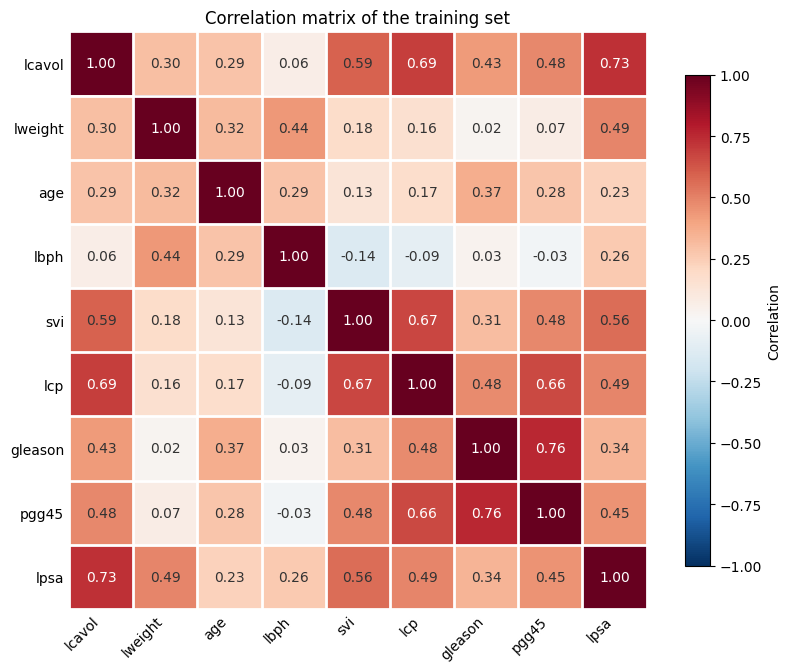

In [7]:
corr_matrix = train_data.corr()

fig, ax = plt.subplots(figsize=(10, 7.5))
im = plot_heatmap(ax, corr_matrix.to_numpy(), corr_matrix.index, corr_matrix.columns, 'RdBu_r', -1, 1)
fig.colorbar(im, ax=ax, label='Correlation', shrink=0.85)
ax.set_title('Correlation matrix of the training set');

Each covariate against the response, with its least squares line.

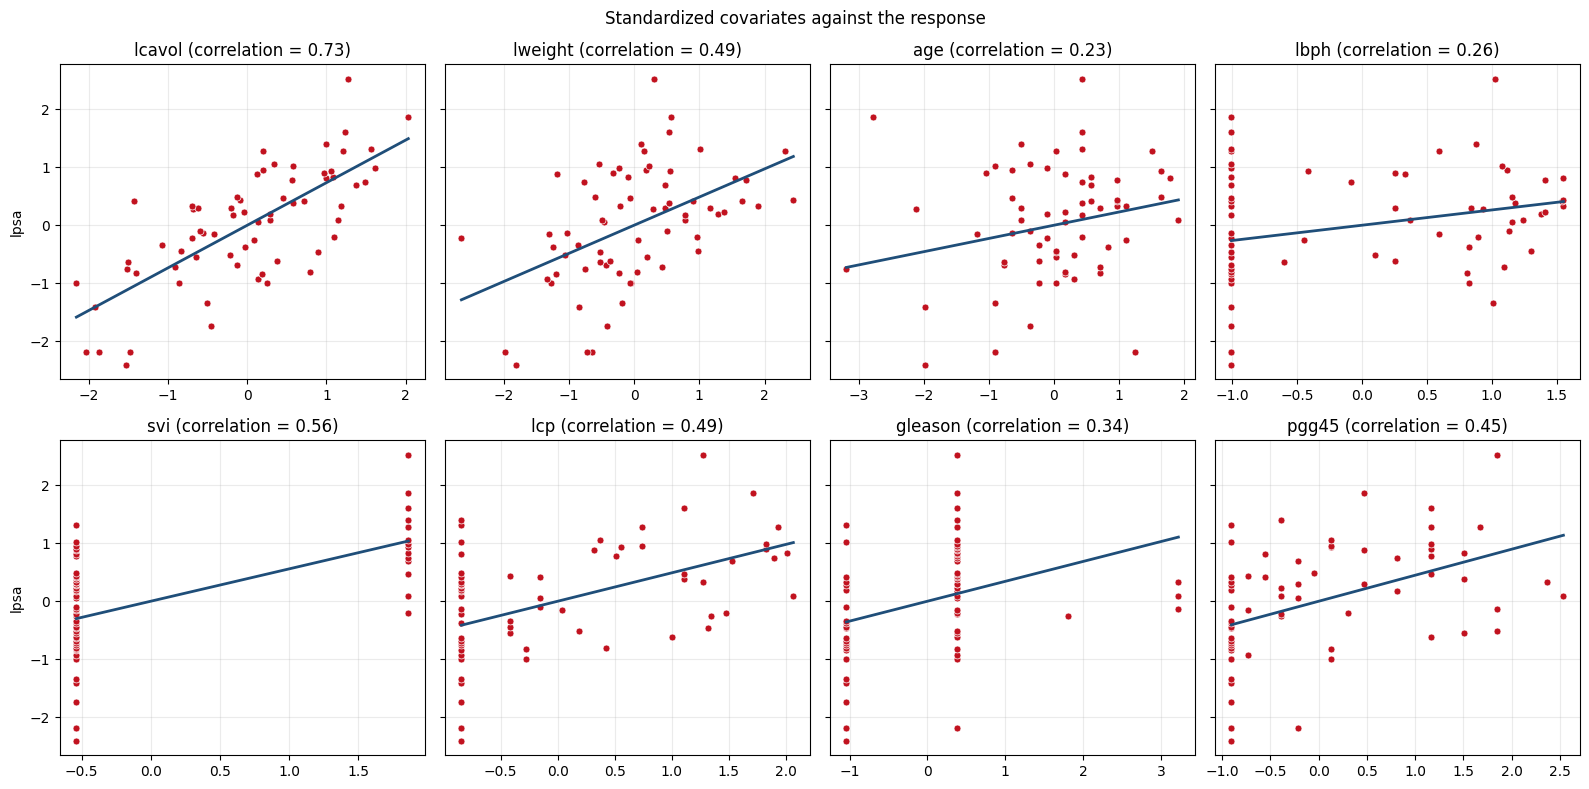

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)
for j, ax in enumerate(axes.ravel()):
    slope = np.polyfit(X_train[:, j], y_train, 1)
    x_line = np.array([X_train[:, j].min(), X_train[:, j].max()])
    ax.plot(X_train[:, j], y_train, 'o', color='#c1121f', markersize=5, markeredgecolor='white', markeredgewidth=0.5)
    ax.plot(x_line, np.polyval(slope, x_line), color='#1f4e79', lw=2)
    ax.set_title(f'{features[j]} (correlation = {corr_matrix.loc[features[j], "lpsa"]:.2f})')
    ax.grid(True, alpha=0.25)
for ax in axes[:, 0]:
    ax.set_ylabel('lpsa')
fig.suptitle('Standardized covariates against the response')
plt.tight_layout()

In [9]:
# Variance inflation factors
# VIFs bigger than 5 might suggest collinearity
vif = pd.DataFrame({
    'feature': features,
    'VIF': np.round([variance_inflation_factor(X_train, j) for j in range(p)], 2)})
vif

,feature,VIF
0,lcavol,2.32
1,lweight,1.47
2,age,1.36
3,lbph,1.38
4,svi,2.05
5,lcp,3.12
6,gleason,2.64
7,pgg45,3.31


In [10]:
# SVD
u, d, vt = np.linalg.svd(X_train)
v = vt.T

# Singular values
d

array([15.15186295, 10.45809199,  8.33410584,  6.43638252,  5.52262052,
        5.02380897,  4.3310785 ,  3.41596048])

In [11]:
# Condition indexes
d[0]/d

array([1.        , 1.44881714, 1.81805502, 2.35409609, 2.74360023,
       3.01601097, 3.49840414, 4.43560838])

All the condition indexes are small, there is no evidence of collinearity. The variance-decomposition proportions are only informative for the rows with a large condition index, and here there is none.

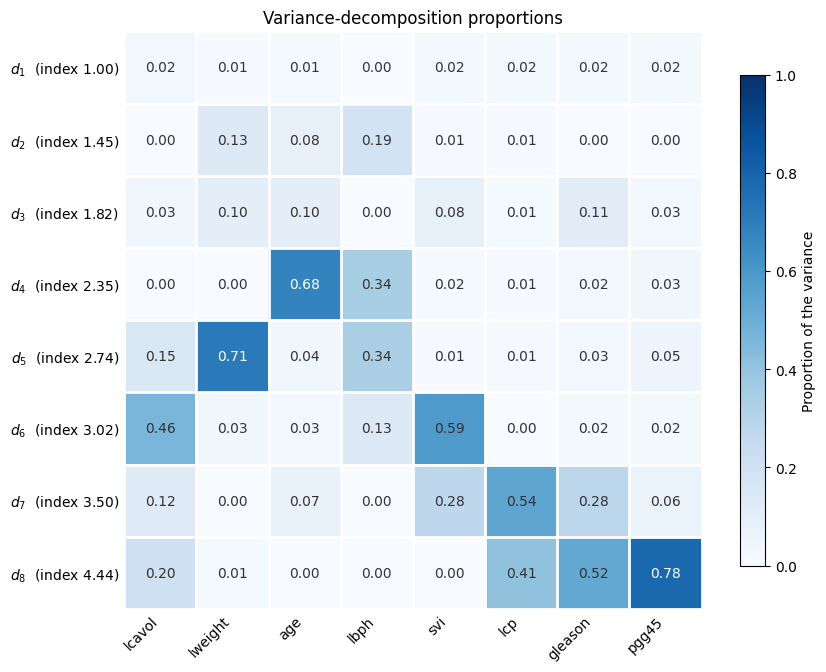

In [12]:
# Variance-decomposition proportions
phis = v**2/d**2
var_decomp_proportions = phis.T/sum(phis.T)

fig, ax = plt.subplots(figsize=(10, 7.5))
row_labels = [f'$d_{k+1}$  (index {d[0]/d[k]:.2f})' for k in range(p)]
im = plot_heatmap(ax, var_decomp_proportions, row_labels, features, 'Blues', 0, 1)
fig.colorbar(im, ax=ax, label='Proportion of the variance', shrink=0.85)
ax.set_title('Variance-decomposition proportions');

## Ridge regression

The ridge estimator minimizes $\|y - X\beta\|^2 + \lambda\|\beta\|^2$,
$$\hat\beta_\lambda = (X^TX + \lambda I)^{-1}X^Ty.$$
A first proposal for the penalty is $\lambda_0 = p\,s^2/\hat\beta^T\hat\beta$, with the least squares estimators (Hoerl, Kennard and Baldwin).

In [13]:
results = sm.OLS(y_train, X_train).fit()
s2 = results.scale
beta_ols = results.params

lambda_0 = p*s2/(beta_ols @ beta_ols)
print('lambda_0:', lambda_0)

lambda_0: 4.398419453190216


By hand, and with `Ridge` from `sklearn` (the variables are standardized, so the intercept is zero)

In [14]:
beta_ridge = np.linalg.solve(X_train.T @ X_train + lambda_0*np.eye(p), X_train.T @ y_train)
ridge = Ridge(alpha=lambda_0).fit(X_train, y_train)

pd.DataFrame({'OLS': beta_ols, 'Ridge by hand': beta_ridge, 'Ridge sklearn': ridge.coef_}, index=features).round(4)

,OLS,Ridge by hand,Ridge sklearn
lcavol,0.5931,0.5140,0.5140
lweight,0.2423,0.2379,0.2379
age,-0.1180,-0.0944,-0.0944
lbph,0.1755,0.1681,0.1681
svi,0.2563,0.2381,0.2381
lcp,-0.2393,-0.1434,-0.1434
gleason,-0.0173,0.0082,0.0082
pgg45,0.2296,0.1758,0.1758


### The ridge trace

We fit the model for a grid of values of $\lambda$. The effective degrees of freedom of the ridge fit are
$$\mathrm{df}(\lambda) = \sum_j \frac{d_j^2}{d_j^2+\lambda},$$
they go from $p$ (least squares, $\lambda=0$) to 0 (all the coefficients are zero, $\lambda=\infty$).

In [15]:
n_lambdas = 200
lambdas = np.logspace(-2, 5, n_lambdas)

df_l = np.array([sum(d**2/(d**2+l)) for l in lambdas])
coefs = np.array([Ridge(alpha=l).fit(X_train, y_train).coef_ for l in lambdas])

In [16]:
def spread(values, gap):
    # Move apart the labels that would overlap
    order = np.argsort(values)
    out = np.array(values, dtype=float)
    for a, b in zip(order[:-1], order[1:]):
        if out[b] - out[a] < gap:
            out[b] = out[a] + gap
    return out

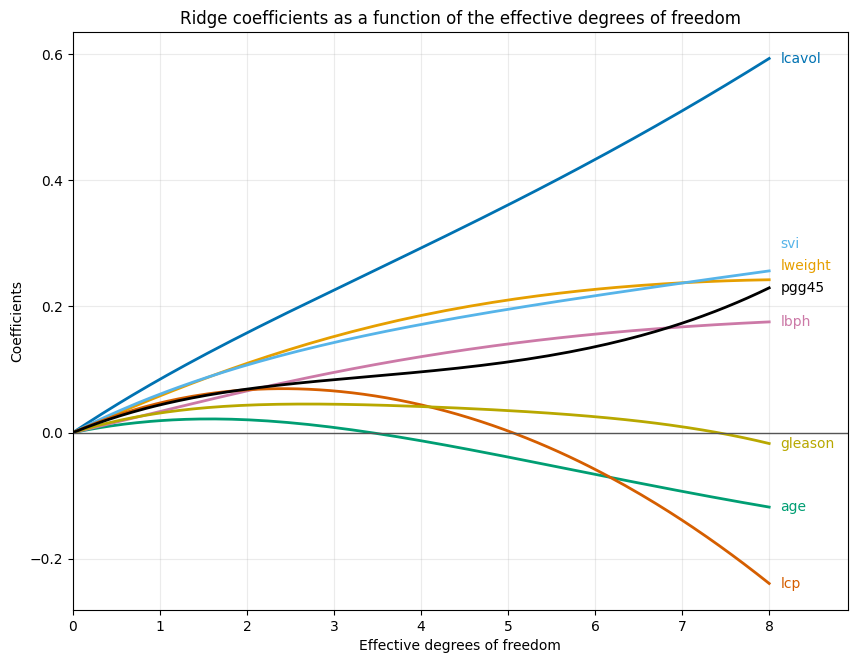

In [17]:
fig, ax = plt.subplots(figsize=(10, 7.5))
for j in range(p):
    ax.plot(df_l, coefs[:, j], color=feature_colors[j], lw=2)
y_labels = spread(coefs[0], 0.035)
for j in range(p):
    ax.annotate(features[j], (df_l[0], y_labels[j]), xytext=(8, 0), textcoords='offset points', va='center',
                fontsize=10, color=feature_colors[j])
ax.axhline(0, color='#555555', lw=1)
ax.set_xlim(0, 8.9)
ax.set_xlabel('Effective degrees of freedom')
ax.set_ylabel('Coefficients')
ax.set_title('Ridge coefficients as a function of the effective degrees of freedom')
ax.grid(True, alpha=0.25)

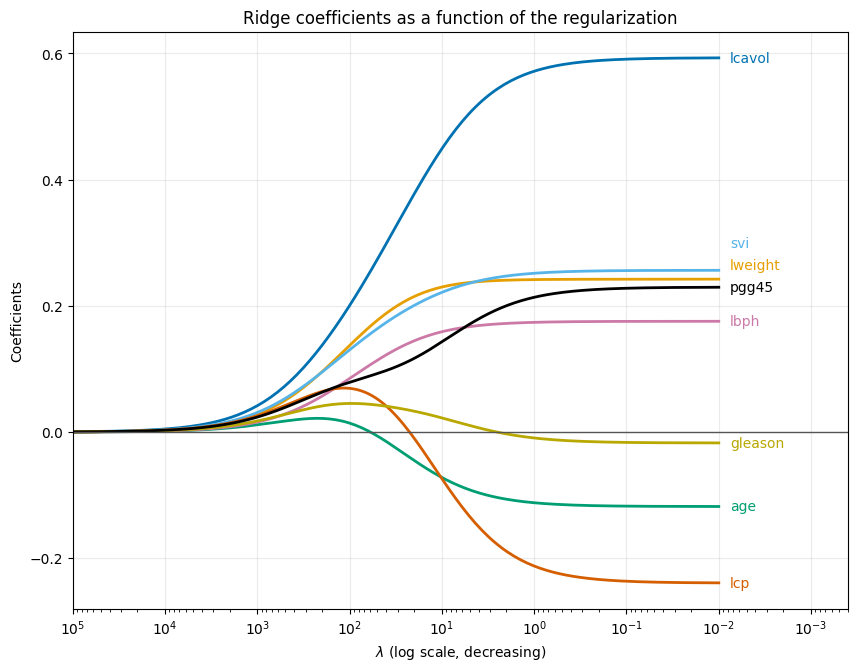

In [18]:
fig, ax = plt.subplots(figsize=(10, 7.5))
for j in range(p):
    ax.plot(lambdas, coefs[:, j], color=feature_colors[j], lw=2)
for j in range(p):
    ax.annotate(features[j], (lambdas[0], y_labels[j]), xytext=(8, 0), textcoords='offset points', va='center',
                fontsize=10, color=feature_colors[j])
ax.axhline(0, color='#555555', lw=1)
ax.set_xscale('log')
ax.set_xlim(1e5, 4e-4)   # decreasing penalty, as in the previous plot
ax.set_xlabel(r'$\lambda$ (log scale, decreasing)')
ax.set_ylabel('Coefficients')
ax.set_title('Ridge coefficients as a function of the regularization')
ax.grid(True, alpha=0.25)

### Choosing the penalty by cross-validation

For each $\lambda$ we estimate the prediction error with leave-one-out cross-validation.

In [19]:
squared_errors = np.zeros((n_train, n_lambdas))

for i, (train_index, valid_index) in enumerate(LeaveOneOut().split(X_train)):
    for j, l in enumerate(lambdas):
        ridge = Ridge(alpha=l).fit(X_train[train_index], y_train[train_index])
        squared_errors[i, j] = (y_train[valid_index] - ridge.predict(X_train[valid_index]))[0]**2

mean_MSE = squared_errors.mean(axis=0)
se_MSE = squared_errors.std(axis=0, ddof=1)/np.sqrt(n_train)

In [20]:
hat_lambda = lambdas[np.argmin(mean_MSE)]
hat_df = sum(d**2/(d**2+hat_lambda))

print('lambda:                      ', hat_lambda)
print('Effective degrees of freedom:', hat_df)
print('Cross-validation MSE:        ', mean_MSE.min())

lambda:                       3.6969127071950285
Effective degrees of freedom: 7.177889284108887
Cross-validation MSE:         0.40112820575752944


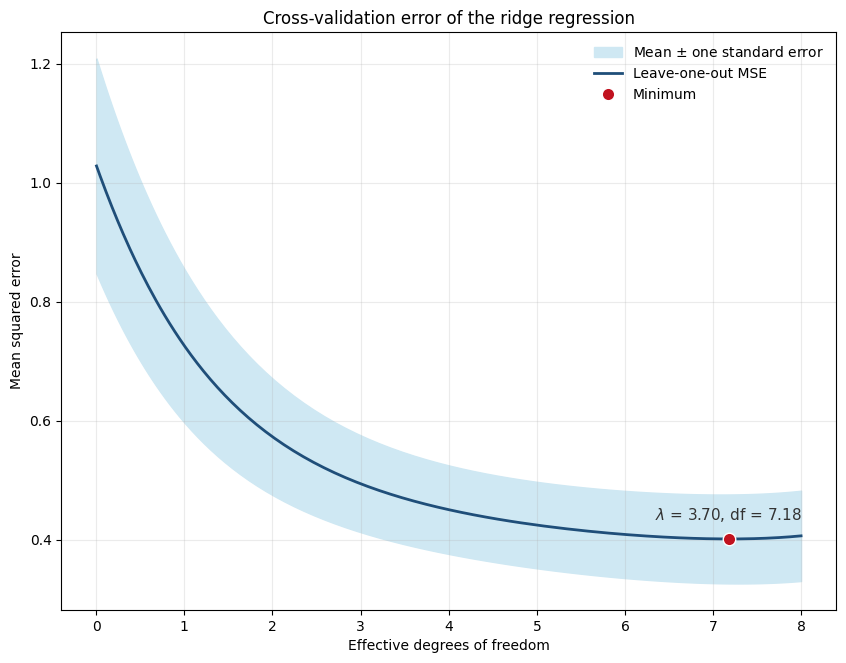

In [21]:
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.fill_between(df_l, mean_MSE-se_MSE, mean_MSE+se_MSE, color='#cfe8f3', label='Mean $\\pm$ one standard error')
ax.plot(df_l, mean_MSE, color='#1f4e79', lw=2, label='Leave-one-out MSE')
ax.plot(hat_df, mean_MSE.min(), 'o', color='#c1121f', markersize=9, markeredgecolor='white', markeredgewidth=1,
        label='Minimum')
ax.annotate(f'$\\lambda$ = {hat_lambda:.2f}, df = {hat_df:.2f}', (hat_df, mean_MSE.min()), xytext=(0, 14),
            textcoords='offset points', ha='center', fontsize=11, color='#333333')
ax.set_xlabel('Effective degrees of freedom')
ax.set_ylabel('Mean squared error')
ax.set_title('Cross-validation error of the ridge regression')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, alpha=0.25)

`RidgeCV` does the same search (it uses an efficient formula for the leave-one-out error).

In [22]:
clf = RidgeCV(alphas=lambdas).fit(X_train, y_train)

print('lambda:              ', clf.alpha_)
print('Cross-validation MSE:', -clf.best_score_)

lambda:               3.6969127071950285
Cross-validation MSE: 0.4011282057575294


In [23]:
pd.DataFrame({'OLS': beta_ols, 'Ridge': clf.coef_}, index=features).round(4)

,OLS,Ridge
lcavol,0.5931,0.5244
lweight,0.2423,0.2387
age,-0.1180,-0.0977
lbph,0.1755,0.1693
svi,0.2563,0.2406
lcp,-0.2393,-0.1554
gleason,-0.0173,0.0054
pgg45,0.2296,0.1820


### Variance of the estimators

The variance inflation factors of least squares are the diagonal of $n(X^TX)^{-1}$. For ridge, the analogous quantity is the diagonal of $n(X^TX+\lambda I)^{-1}X^TX(X^TX+\lambda I)^{-1}$: the price of the bias is a smaller variance.

In [24]:
aux = np.linalg.inv(X_train.T @ X_train + clf.alpha_*np.eye(p))
ridge_vifs = n_train*np.diag(aux @ X_train.T @ X_train @ aux)
ols_vifs = n_train*np.diag(np.linalg.inv(X_train.T @ X_train))

pd.DataFrame({'OLS': ols_vifs, 'Ridge': ridge_vifs}, index=features).round(4)

,OLS,Ridge
lcavol,2.3185,1.6939
lweight,1.4723,1.2092
age,1.3566,1.1435
lbph,1.3834,1.1531
svi,2.0453,1.5599
lcp,3.1175,2.0572
gleason,2.6445,1.7689
pgg45,3.3133,2.0737


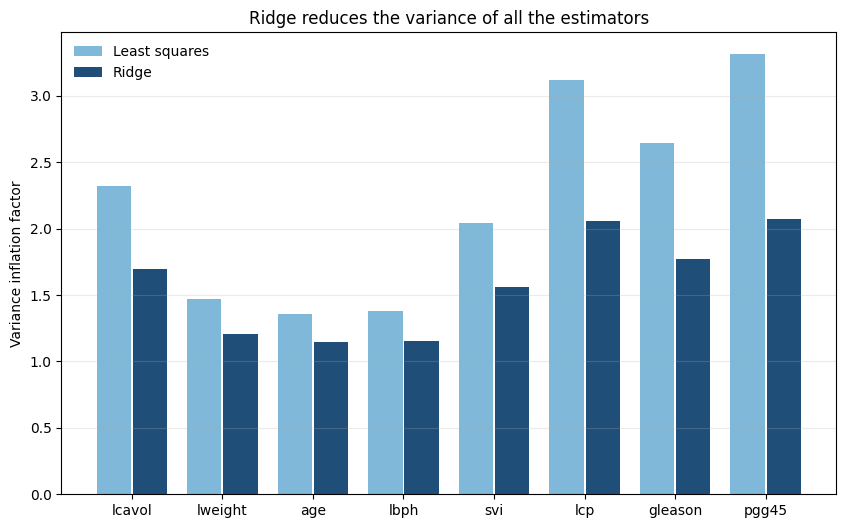

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))
pos = np.arange(p)
ax.bar(pos-0.2, ols_vifs, width=0.38, color='#7fb8d8', label='Least squares')
ax.bar(pos+0.2, ridge_vifs, width=0.38, color='#1f4e79', label='Ridge')
ax.set_xticks(pos, features)
ax.set_ylabel('Variance inflation factor')
ax.set_title('Ridge reduces the variance of all the estimators')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, axis='y', alpha=0.25)

### Error in the testing set

In [26]:
print('Test MSE, least squares:', mean_squared_error(y_test, results.predict(X_test)))
print('Test MSE, ridge:        ', mean_squared_error(y_test, clf.predict(X_test)))

Test MSE, least squares: 0.36274235770375995
Test MSE, ridge:         0.34662824067307246


## The effect of the penalty

Move the slider to see how the coefficients shrink as $\lambda$ grows (this cell needs a running kernel).

In [27]:
def plot_coefficients(ax, l):
    beta = np.linalg.solve(X_train.T @ X_train + l*np.eye(p), X_train.T @ y_train)
    ax.barh(np.arange(p), beta_ols, height=0.7, color='#dddddd', label='Least squares')
    ax.barh(np.arange(p), beta, height=0.42, color=feature_colors, label='Ridge')
    ax.axvline(0, color='#555555', lw=1)
    ax.set_yticks(np.arange(p), features)
    ax.invert_yaxis()
    ax.set_xlim(-0.35, 0.8)
    ax.set_xlabel('Coefficient')
    ax.set_title(f'$\\lambda$ = {l:.3g}, df = {sum(d**2/(d**2+l)):.2f}')
    ax.grid(True, axis='x', alpha=0.25)

def interactive_ridge(l):
    fig, ax = plt.subplots(figsize=(10, 6))
    plot_coefficients(ax, l)
    plt.show()

interact(interactive_ridge, l=FloatLogSlider(value=clf.alpha_, base=10, min=-2, max=5, step=0.05, description='lambda'));

interactive(children=(FloatLogSlider(value=3.6969127071950285, description='lambda', max=5.0, min=-2.0, step=0…

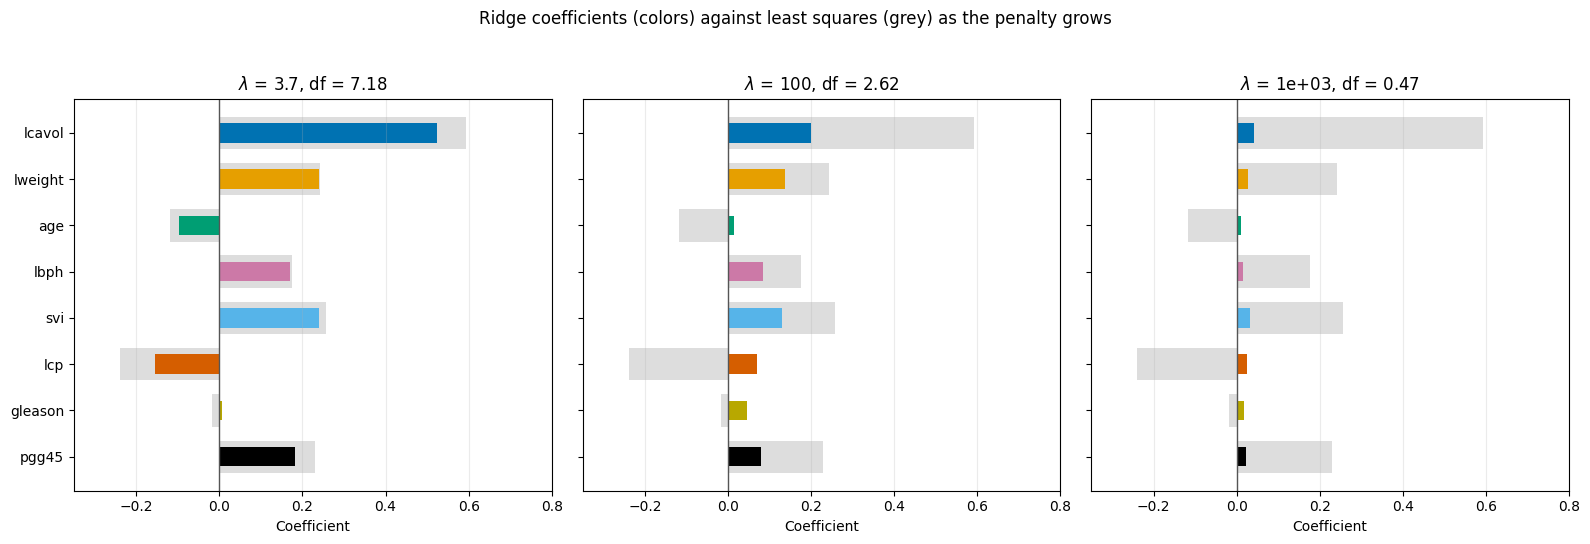

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True)
for ax, l in zip(axes, [clf.alpha_, 100, 1000]):
    plot_coefficients(ax, l)
fig.suptitle('Ridge coefficients (colors) against least squares (grey) as the penalty grows')
fig.tight_layout(rect=(0, 0, 1, 0.95))